[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BrianAranda/Informes_FDPI/blob/tp3/code/ejercicio_2/ejercicio_2.ipynb)

# TP N.º 3 · Actividad 2: Filtros de preservación de bordes (Bilateral vs. Gaussiano)

**Objetivo.** Contaminar una imagen de referencia limpia con ruido gaussiano moderado ($\sigma \approx 20$–$25$) y comparar el **filtro gaussiano** con el **filtro bilateral**:

- Gaussiano con $\sigma_{esp} \in \{2, 4, 6\}$.
- Bilateral con $\sigma_{esp} \in \{2, 4, 6\}$ y $\sigma_{rango} \in \{20, 50, 100\}$.
- Comparación visual en **regiones de borde** y **regiones homogéneas**.
- Métricas **MSE**, **PSNR** y **SSIM**; las decisiones se toman priorizando **SSIM** y **PSNR**.
- Mapa SSIM local de la mejor y la peor configuración.
- Costo computacional medido con repeticiones.
- Desempeño frente a los ruidos más comunes: gaussiano, sal y pimienta, aleatorio y cuantificación.

Imagen de trabajo: `img/ejercicio_2/disqueria.jpeg`. Las figuras para el informe se guardan en `img/ejercicio_2/`.

In [1]:
# Entorno: en Colab clona el repositorio y se ubica en code/ejercicio_2. En local no hace nada.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    RAMA = "tp3"
    REPO = "https://github.com/BrianAranda/Informes_FDPI.git"
    DESTINO = "/content/Informes_FDPI"
    if not os.path.isdir(DESTINO):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", RAMA, REPO, DESTINO], check=True)
    os.chdir(f"{DESTINO}/code/ejercicio_2")
    print("Trabajando en", os.getcwd())

## 1. Configuración

In [2]:
import timeit
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio, structural_similarity

RUTA_IMG = Path("../../img/ejercicio_2/disqueria.jpeg")
SALIDA = Path("../../img/ejercicio_2")      # figuras para el informe
SALIDA.mkdir(parents=True, exist_ok=True)

LADO = 1024          # resolución de trabajo (px)
SEMILLA = 42         # reproducibilidad del ruido
SIGMA_RUIDO = 25     # ruido gaussiano moderado (consigna: 20-25)
SIGMAS_ESP = [2, 4, 6]
SIGMAS_RANGO = [20, 50, 100]

plt.rcParams.update({
    "font.family": "STIXGeneral", "mathtext.fontset": "stix",
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 8, "figure.dpi": 100,
    "savefig.dpi": 300, "savefig.bbox": "tight",
})

def a_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def guardar_fig(fig, nombre):
    fig.savefig(SALIDA / nombre)
    print("Figura guardada:", SALIDA / nombre)

def guardar_img(img, nombre, escala=1):
    if escala != 1:
        img = cv2.resize(img, None, fx=escala, fy=escala, interpolation=cv2.INTER_NEAREST)
    if nombre.endswith(".jpg"):
        cv2.imwrite(str(SALIDA / nombre), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    else:
        cv2.imwrite(str(SALIDA / nombre), img)

## 2. Imagen de referencia (*ground truth*)

La foto original es de un celular (6120 × 6120 px, ~37 MP). Se reduce a 1024 × 1024 con `INTER_AREA`, que promedia bloques de ~6 × 6 píxeles. Esto cumple dos funciones:

1. **Limpia la referencia:** el promedio atenúa el ruido propio del sensor, tomado con poca luz.
2. **Vuelve viable el experimento:** el bilateral sobre 37 MP tardaría segundos por configuración.

Se definen dos regiones de interés (ROI): **borde** (guitarras contra la pared) y **homogénea** (pared lisa), más una línea de perfil que cruza las guitarras.

In [3]:
original = cv2.imread(str(RUTA_IMG), cv2.IMREAD_COLOR)
assert original is not None, f"No se encontró la imagen en {RUTA_IMG.resolve()}"
print("Tamaño original:", original.shape)

ref = cv2.resize(original, (LADO, LADO), interpolation=cv2.INTER_AREA)
print("Tamaño de trabajo:", ref.shape)

# Regiones de interés (x, y, ancho, alto) y línea de perfil
ROI_BORDE = (320, 36, 256, 256)     # guitarras sobre la pared
ROI_HOMOG = (670, 50, 145, 145)     # pared lisa
PERFIL_Y, PERFIL_X0, PERFIL_X1 = 230, 300, 660

def recortar(img, roi):
    x, y, w, h = roi
    return img[y:y + h, x:x + w]

vista = ref.copy()
cv2.rectangle(vista, ROI_BORDE[:2], (ROI_BORDE[0] + ROI_BORDE[2], ROI_BORDE[1] + ROI_BORDE[3]), (0, 0, 255), 4)
cv2.rectangle(vista, ROI_HOMOG[:2], (ROI_HOMOG[0] + ROI_HOMOG[2], ROI_HOMOG[1] + ROI_HOMOG[3]), (0, 200, 0), 4)
cv2.line(vista, (PERFIL_X0, PERFIL_Y), (PERFIL_X1, PERFIL_Y), (255, 120, 0), 3)
guardar_img(vista, "original_rois.jpg")

Tamaño original: (6120, 6120, 3)
Tamaño de trabajo: (1024, 1024, 3)


## 3. Contaminación con ruido gaussiano

Ruido aditivo $n \sim \mathcal{N}(0, \sigma^2)$ con $\sigma = 25$, independiente por píxel y por canal, con recorte a $[0, 255]$. También se definen los otros ruidos típicos que se usan en la sección 9.

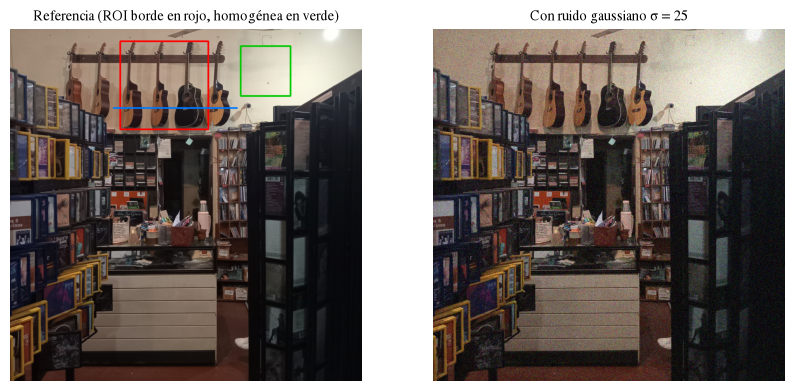

In [4]:
def ruido_gaussiano(img, sigma, rng):
    return np.clip(img.astype(np.float64) + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)

def ruido_sal_pimienta(img, densidad, rng):
    # el impulso afecta los tres canales del píxel (píxel muerto o saturado)
    out = img.copy()
    u = rng.random(img.shape[:2])
    out[u < densidad / 2] = 0
    out[(u >= densidad / 2) & (u < densidad)] = 255
    return out

def ruido_uniforme(img, amplitud, rng):
    return np.clip(img.astype(np.float64) + rng.uniform(-amplitud, amplitud, img.shape), 0, 255).astype(np.uint8)

def cuantificar(img, niveles):
    paso = 256 / niveles
    return np.clip(np.floor(img / paso) * paso + paso / 2, 0, 255).astype(np.uint8)

ruidosa = ruido_gaussiano(ref, SIGMA_RUIDO, np.random.default_rng(SEMILLA))
guardar_img(ruidosa, "ruidosa_gauss25.jpg")

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(a_rgb(vista)); ax[0].set_title("Referencia (ROI borde en rojo, homogénea en verde)")
ax[1].imshow(a_rgb(ruidosa)); ax[1].set_title(f"Con ruido gaussiano σ = {SIGMA_RUIDO}")
for a in ax: a.axis("off")
plt.show()

## 4. Métricas

| Métrica | Cálculo | Lectura |
|---|---|---|
| MSE | $\frac{1}{N}\sum (x-y)^2$ | 0 = idénticas; en niveles² |
| PSNR | $10\log_{10}(255^2/\mathrm{MSE})$ [dB] | mayor es mejor; >30 dB bueno |
| SSIM | luminancia · contraste · estructura en ventanas locales | 1 = idénticas; mide la estructura |

Se usa siempre `data_range=255` fijo y SSIM sobre los tres canales (`channel_axis=2`). Los tiempos se miden con `timeit.repeat` (7 repeticiones × 3 ejecuciones) y se reporta la mediana (robusta ante interrupciones del sistema) junto al desvío.

In [5]:
def metricas(ref, img):
    return {
        "MSE": mean_squared_error(ref, img),
        "PSNR": peak_signal_noise_ratio(ref, img, data_range=255),
        "SSIM": structural_similarity(ref, img, channel_axis=2, data_range=255),
    }

def medir_tiempo(fn, repeticiones=7, numero=3):
    # se usa la mediana: es robusta a interrupciones del sistema operativo
    t = np.array(timeit.repeat(fn, repeat=repeticiones, number=numero)) / numero * 1000
    return np.median(t), t.std()

def aplicar(img, filtro, s_esp, s_rango=None):
    if filtro == "Gaussiano":
        return cv2.GaussianBlur(img, (0, 0), s_esp)            # ventana = 6σ+1 (uint8)
    return cv2.bilateralFilter(img, 0, s_rango, s_esp)        # d=0: ventana desde σ_esp

# Ventanas que usa OpenCV internamente (para documentar)
for s in SIGMAS_ESP:
    k_gauss = int(round(s * 3 * 2 + 1)) | 1
    d_bil = 2 * int(round(s * 1.5)) + 1
    print(f"σ_esp={s}: ventana gaussiana {k_gauss}×{k_gauss} | ventana bilateral {d_bil}×{d_bil}")

print("Ruidosa:", {k: round(v, 3) for k, v in metricas(ref, ruidosa).items()})

σ_esp=2: ventana gaussiana 13×13 | ventana bilateral 7×7
σ_esp=4: ventana gaussiana 25×25 | ventana bilateral 13×13
σ_esp=6: ventana gaussiana 37×37 | ventana bilateral 19×19


Ruidosa: {'MSE': np.float64(527.415), 'PSNR': np.float64(20.909), 'SSIM': np.float64(0.302)}


## 5. Barrido de parámetros: Gaussiano vs. Bilateral

Las configuraciones se ordenan por el **puesto promedio** entre el ranking de SSIM y el de PSNR (menor es mejor). Si hay empate, decide el SSIM.

In [6]:
configs = [("Gaussiano", s, None) for s in SIGMAS_ESP] + \
          [("Bilateral", s, r) for s in SIGMAS_ESP for r in SIGMAS_RANGO]

filas, salidas = [], {}
for filtro, s, r in configs:
    out = aplicar(ruidosa, filtro, s, r)
    salidas[(filtro, s, r)] = out
    t_med, t_desv = medir_tiempo(lambda: aplicar(ruidosa, filtro, s, r))
    filas.append({"Filtro": filtro, "σ_esp": s, "σ_rango": r if r else "–",
                  **metricas(ref, out), "Tiempo [ms]": t_med, "Desvío [ms]": t_desv})

df = pd.DataFrame(filas)
df["Rank SSIM"] = df["SSIM"].rank(ascending=False)
df["Rank PSNR"] = df["PSNR"].rank(ascending=False)
df["Puesto"] = (df["Rank SSIM"] + df["Rank PSNR"]) / 2
df = df.sort_values(["Puesto", "SSIM"], ascending=[True, False]).reset_index(drop=True)

base = metricas(ref, ruidosa)
print(f"Ruidosa: MSE={base['MSE']:.1f}  PSNR={base['PSNR']:.2f} dB  SSIM={base['SSIM']:.3f}")
df.round({"MSE": 1, "PSNR": 2, "SSIM": 3, "Tiempo [ms]": 1, "Desvío [ms]": 1, "Puesto": 1})

Ruidosa: MSE=527.4  PSNR=20.91 dB  SSIM=0.302


,Filtro,σ_esp,σ_rango,MSE,PSNR,SSIM,Tiempo [ms],Desvío [ms],Rank SSIM,Rank PSNR,Puesto
0,Bilateral,4,100,67.5,29.84,0.814,67.0,3.8,1.0,2.0,1.5
1,Bilateral,6,100,80.9,29.05,0.802,153.5,5.6,2.0,3.0,2.5
2,Bilateral,2,100,66.3,29.92,0.761,19.6,1.3,4.0,1.0,2.5
3,Gaussiano,2,–,152.3,26.30,0.769,4.8,0.4,3.0,6.0,4.5
4,Bilateral,6,50,109.2,27.75,0.624,149.7,5.6,7.0,4.0,5.5
5,Gaussiano,4,–,256.6,24.04,0.696,14.2,3.4,5.0,8.0,6.5
6,Bilateral,4,50,112.5,27.62,0.618,67.6,2.3,8.0,5.0,6.5
7,Gaussiano,6,–,348.8,22.70,0.646,17.3,1.5,6.0,9.0,7.5
8,Bilateral,2,50,153.9,26.26,0.548,17.2,0.8,9.0,7.0,8.0
9,Bilateral,6,20,376.1,22.38,0.357,152.4,7.4,10.0,10.0,10.0


In [7]:
mejor = df.iloc[0]
peor = df.iloc[-1]
mejor_gauss = df[df["Filtro"] == "Gaussiano"].iloc[0]
CLAVE_MEJOR = (mejor["Filtro"], int(mejor["σ_esp"]), None if mejor["σ_rango"] == "–" else int(mejor["σ_rango"]))
CLAVE_PEOR = (peor["Filtro"], int(peor["σ_esp"]), None if peor["σ_rango"] == "–" else int(peor["σ_rango"]))
CLAVE_GAUSS = ("Gaussiano", int(mejor_gauss["σ_esp"]), None)

def nombre(clave):
    f, s, r = clave
    return f"Gaussiano σ={s}" if f == "Gaussiano" else f"Bilateral σ_esp={s}, σ_rango={r}"

def nombre_fig(clave):   # misma etiqueta, con subíndices para las figuras
    f, s, r = clave
    return f"Gaussiano σ={s}" if f == "Gaussiano" else f"Bilateral σ$_{{esp}}$={s}, σ$_{{rango}}$={r}"

print("Mejor configuración :", nombre(CLAVE_MEJOR), f"→ SSIM {mejor['SSIM']:.3f}, PSNR {mejor['PSNR']:.2f} dB")
print("Mejor gaussiano     :", nombre(CLAVE_GAUSS), f"→ SSIM {mejor_gauss['SSIM']:.3f}, PSNR {mejor_gauss['PSNR']:.2f} dB")
print("Peor configuración  :", nombre(CLAVE_PEOR), f"→ SSIM {peor['SSIM']:.3f}, PSNR {peor['PSNR']:.2f} dB")

t_g = df[df["Filtro"] == "Gaussiano"]["Tiempo [ms]"]
t_b = df[df["Filtro"] == "Bilateral"]["Tiempo [ms]"]
print(f"Tiempo gaussiano: {t_g.min():.1f}–{t_g.max():.1f} ms | bilateral: {t_b.min():.1f}–{t_b.max():.1f} ms")
print(f"Mejor bilateral vs. mejor gaussiano: {mejor['Tiempo [ms]'] / mejor_gauss['Tiempo [ms]']:.1f} veces más lento")

Mejor configuración : Bilateral σ_esp=4, σ_rango=100 → SSIM 0.814, PSNR 29.84 dB
Mejor gaussiano     : Gaussiano σ=2 → SSIM 0.769, PSNR 26.30 dB
Peor configuración  : Bilateral σ_esp=2, σ_rango=20 → SSIM 0.326, PSNR 21.52 dB
Tiempo gaussiano: 4.8–17.3 ms | bilateral: 17.1–153.5 ms
Mejor bilateral vs. mejor gaussiano: 13.9 veces más lento


### Curvas de SSIM y PSNR en función de $\sigma_{rango}$

Figura guardada: ..\..\img\ejercicio_2\curvas_metricas.pdf


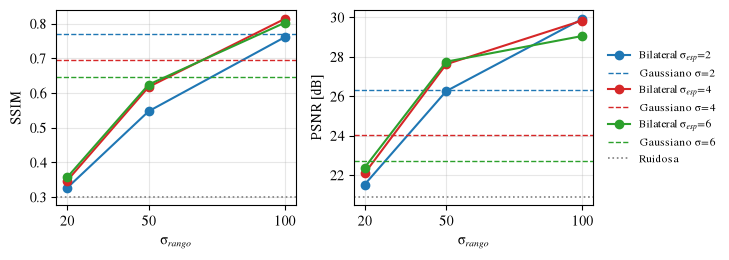

In [8]:
colores = {2: "#1f77b4", 4: "#d62728", 6: "#2ca02c"}
fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.7))
for j, met in enumerate(["SSIM", "PSNR"]):
    for s in SIGMAS_ESP:
        vals = [metricas(ref, salidas[("Bilateral", s, r)])[met] for r in SIGMAS_RANGO]
        ax[j].plot(SIGMAS_RANGO, vals, "o-", color=colores[s], label=f"Bilateral σ$_{{esp}}$={s}")
        g = metricas(ref, salidas[("Gaussiano", s, None)])[met]
        ax[j].axhline(g, color=colores[s], ls="--", lw=1, label=f"Gaussiano σ={s}")
    ax[j].axhline(base[met], color="gray", ls=":", lw=1.2, label="Ruidosa")
    ax[j].set_xlabel("σ$_{rango}$"); ax[j].set_ylabel(met + (" [dB]" if met == "PSNR" else ""))
    ax[j].set_xticks(SIGMAS_RANGO); ax[j].grid(alpha=0.3)
ax[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
guardar_fig(fig, "curvas_metricas.pdf")
plt.show()

### ¿Cuándo el bilateral se parece a un gaussiano?

Con $\sigma_{rango}$ muy grande el peso de rango vale ≈ 1 para cualquier diferencia de color y el bilateral se reduce a un gaussiano espacial. OpenCV trunca la ventana del bilateral en un radio de $1{,}5\,\sigma_{esp}$, por eso se compara contra un gaussiano con esa misma ventana.

In [9]:
s = 4
radio = int(round(1.5 * s))
g_trunc = cv2.GaussianBlur(ruidosa, (2 * radio + 1, 2 * radio + 1), s)
for sr in [100, 1000, 10000]:
    b = cv2.bilateralFilter(ruidosa, 0, sr, s)
    print(f"σ_rango={sr:>5}: PSNR(bilateral, gaussiano truncado)={peak_signal_noise_ratio(g_trunc, b, data_range=255):.1f} dB"
          f" | SSIM vs ref={metricas(ref, b)['SSIM']:.3f}")
print(f"Gaussiano truncado {2*radio+1}×{2*radio+1}: SSIM vs ref={metricas(ref, g_trunc)['SSIM']:.3f}")

σ_rango=  100: PSNR(bilateral, gaussiano truncado)=27.3 dB | SSIM vs ref=0.814


σ_rango= 1000: PSNR(bilateral, gaussiano truncado)=43.0 dB | SSIM vs ref=0.729


σ_rango=10000: PSNR(bilateral, gaussiano truncado)=43.6 dB | SSIM vs ref=0.724


Gaussiano truncado 13×13: SSIM vs ref=0.708


## 6. Comparación visual: regiones de borde y homogéneas

Se fija $\sigma_{esp} = 4$ para comparar ambos filtros a la **misma escala espacial** y se varía $\sigma_{rango}$.

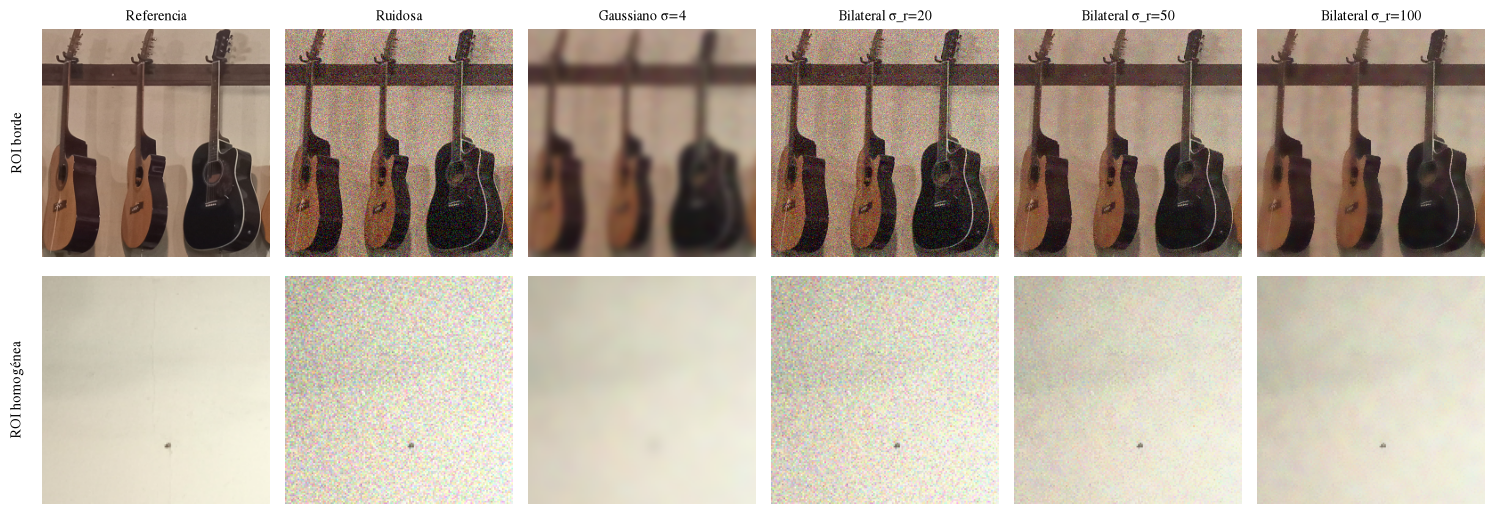

In [10]:
S_VIS = 4
paneles = [("Referencia", ref), ("Ruidosa", ruidosa), (f"Gaussiano σ={S_VIS}", salidas[("Gaussiano", S_VIS, None)])] + \
          [(f"Bilateral σ_r={r}", salidas[("Bilateral", S_VIS, r)]) for r in SIGMAS_RANGO]
archivos = ["original", "ruidosa", f"gauss_s{S_VIS}"] + [f"bil_s{S_VIS}_r{r}" for r in SIGMAS_RANGO]

fig, ax = plt.subplots(2, len(paneles), figsize=(15, 5.4))
for i, (roi, etiqueta) in enumerate([(ROI_BORDE, "borde"), (ROI_HOMOG, "homog")]):
    for j, ((titulo, img), arch) in enumerate(zip(paneles, archivos)):
        rec = recortar(img, roi)
        ax[i, j].imshow(a_rgb(rec)); ax[i, j].axis("off")
        if i == 0: ax[i, j].set_title(titulo)
        guardar_img(rec, f"roi_{etiqueta}_{arch}.png", escala=2 if etiqueta == "borde" else 3)
ax[0, 0].text(-20, 128, "ROI borde", rotation=90, va="center", ha="right")
ax[1, 0].text(-12, 72, "ROI homogénea", rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

### Métricas por región

- **Bordes:** Canny sobre la referencia, dilatado 5 × 5.
- **Homogéneas:** desvío local menor a 4 niveles en ventanas de 9 × 9, excluyendo los bordes.

El SSIM de cada región es el promedio del mapa SSIM local dentro de la máscara.

In [11]:
gris = cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY)
mask_borde = cv2.dilate(cv2.Canny(gris, 50, 150), np.ones((5, 5), np.uint8)) > 0
g = gris.astype(np.float64)
desv_local = np.sqrt(np.maximum(cv2.blur(g ** 2, (9, 9)) - cv2.blur(g, (9, 9)) ** 2, 0))
mask_homog = (desv_local < 4) & ~mask_borde
print(f"Píxeles de borde: {mask_borde.mean()*100:.1f} % | homogéneos: {mask_homog.mean()*100:.1f} %")

def metricas_region(ref, img, mask):
    _, mapa = structural_similarity(ref, img, channel_axis=2, data_range=255, full=True)
    mapa = mapa.mean(axis=2)
    err = ((ref.astype(np.float64) - img.astype(np.float64)) ** 2).mean(axis=2)
    mse = err[mask].mean()
    return mse, 10 * np.log10(255 ** 2 / mse), mapa[mask].mean()

candidatos = [("Ruidosa", ruidosa), (nombre(CLAVE_GAUSS), salidas[CLAVE_GAUSS]),
              (f"Gaussiano σ={S_VIS}", salidas[("Gaussiano", S_VIS, None)]),
              (nombre(CLAVE_MEJOR), salidas[CLAVE_MEJOR])]
filas_reg = []
for nom, img in candidatos:
    fila = {"Imagen": nom}
    for reg, m in [("Bordes", mask_borde), ("Homogéneas", mask_homog)]:
        _, p, s_ = metricas_region(ref, img, m)
        fila[f"PSNR {reg}"] = p; fila[f"SSIM {reg}"] = s_
    filas_reg.append(fila)
df_reg = pd.DataFrame(filas_reg)
df_reg.round(3)

Píxeles de borde: 32.2 % | homogéneos: 48.2 %


,Imagen,PSNR Bordes,SSIM Bordes,PSNR Homogéneas,SSIM Homogéneas
0,Ruidosa,20.550,0.610,21.182,0.123
1,Gaussiano σ=2,21.930,0.632,34.618,0.866
2,Gaussiano σ=4,19.783,0.412,34.752,0.899
3,"Bilateral σ_esp=4, σ_rango=100",26.336,0.812,34.593,0.831


### Perfil de intensidad a través de los bordes de las guitarras

Figura guardada: ..\..\img\ejercicio_2\perfil_borde.pdf


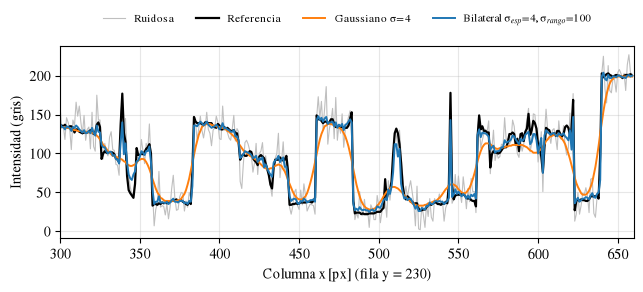

In [12]:
def perfil(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)[PERFIL_Y, PERFIL_X0:PERFIL_X1].astype(float)

x = np.arange(PERFIL_X0, PERFIL_X1)
fig, ax = plt.subplots(figsize=(7.4, 2.5))
ax.plot(x, perfil(ruidosa), color="0.75", lw=0.8, label="Ruidosa")
ax.plot(x, perfil(ref), color="k", lw=1.6, label="Referencia")
ax.plot(x, perfil(salidas[("Gaussiano", S_VIS, None)]), color="#ff7f0e", lw=1.4, label=f"Gaussiano σ={S_VIS}")
ax.plot(x, perfil(salidas[CLAVE_MEJOR]), color="#1f77b4", lw=1.4,
        label=f"Bilateral σ$_{{esp}}$={CLAVE_MEJOR[1]}, σ$_{{rango}}$={CLAVE_MEJOR[2]}")
ax.set_xlabel("Columna x [px] (fila y = %d)" % PERFIL_Y); ax.set_ylabel("Intensidad (gris)")
ax.set_xlim(PERFIL_X0, PERFIL_X1); ax.grid(alpha=0.3)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.22), frameon=False)
guardar_fig(fig, "perfil_borde.pdf")
plt.show()

## 7. Mapa SSIM local: mejor vs. peor configuración

Referencia visual de las zonas con alta y baja similitud estructural respecto de la imagen limpia.

Figura guardada: ..\..\img\ejercicio_2\mapa_ssim.png


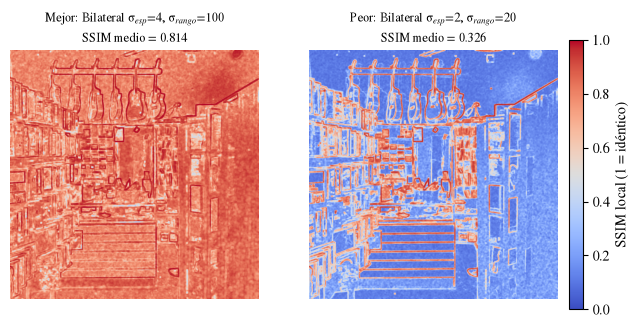

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.5))
for a, clave, rot in [(ax[0], CLAVE_MEJOR, "Mejor"), (ax[1], CLAVE_PEOR, "Peor")]:
    val, mapa = structural_similarity(ref, salidas[clave], channel_axis=2, data_range=255, full=True)
    im = a.imshow(mapa.mean(axis=2), cmap="coolwarm", vmin=0, vmax=1)
    a.set_title(f"{rot}: {nombre_fig(clave)}\nSSIM medio = {val:.3f}", fontsize=9)
    a.axis("off")
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label("SSIM local (1 = idéntico)")
fig.savefig(SALIDA / "mapa_ssim.png", dpi=200)
print("Figura guardada:", SALIDA / "mapa_ssim.png")
plt.show()

## 8. Desempeño frente a los tipos de ruido más comunes

Ruidos típicos del notebook de la cátedra: **gaussiano**, **sal y pimienta**, **aleatorio** (modelado como uniforme en ±43, con la misma varianza que σ = 25) y **cuantificación** (8 niveles por canal, 3 bits).

Para cada uno se busca la mejor configuración de cada filtro en la misma grilla, según el puesto promedio SSIM + PSNR. La **mediana** (3 × 3 y 5 × 5) se agrega solo como referencia.

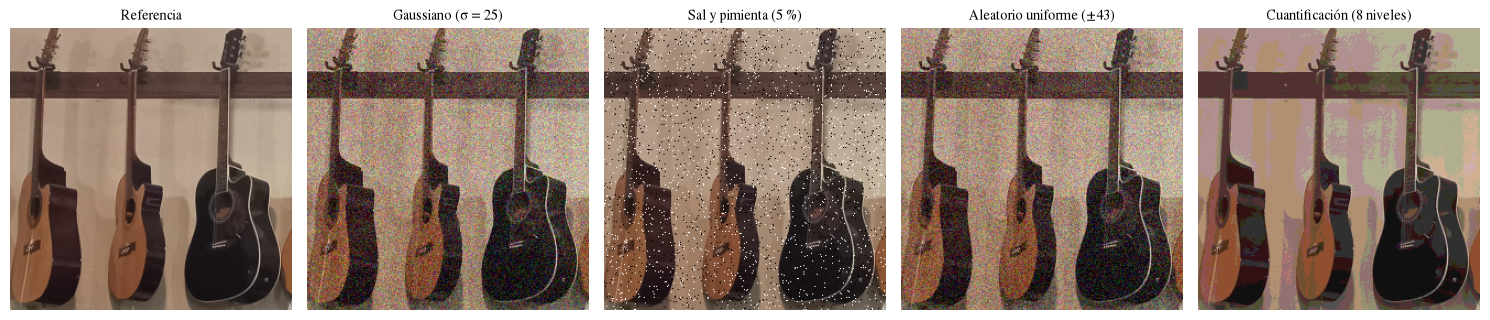

Celdas: PSNR [dB] / SSIM. Bilateral: (σ_esp, σ_rango)


,Ruido,Sin filtrar,Gaussiano,Bilateral,Mediana (ref.)
0,Gaussiano (σ = 25),20.90 / 0.301,σ=2: 26.30 / 0.769,"(4, 100): 29.84 / 0.814",5×5: 26.49 / 0.672
1,Sal y pimienta (5 %),17.50 / 0.360,σ=2: 25.62 / 0.719,"(2, 100): 17.61 / 0.365",3×3: 31.46 / 0.945
2,Aleatorio uniforme (±43),20.84 / 0.297,σ=2: 26.27 / 0.766,"(4, 100): 29.55 / 0.795",5×5: 25.73 / 0.590
3,Cuantificación (8 niveles),29.30 / 0.843,σ=2: 25.96 / 0.787,"(4, 50): 31.19 / 0.904",3×3: 27.41 / 0.813


In [14]:
rng = np.random.default_rng(SEMILLA + 1)
ruidos = {
    "Gaussiano (σ = 25)": ruido_gaussiano(ref, 25, rng),
    "Sal y pimienta (5 %)": ruido_sal_pimienta(ref, 0.05, rng),
    "Aleatorio uniforme (±43)": ruido_uniforme(ref, 43, rng),
    "Cuantificación (8 niveles)": cuantificar(ref, 8),
}
nombres_arch = ["gauss", "sp", "unif", "cuant"]

fig, ax = plt.subplots(1, 5, figsize=(15, 3.3))
ax[0].imshow(a_rgb(recortar(ref, ROI_BORDE))); ax[0].set_title("Referencia")
for a, (nom, img), arch in zip(ax[1:], ruidos.items(), nombres_arch):
    a.imshow(a_rgb(recortar(img, ROI_BORDE))); a.set_title(nom)
    guardar_img(recortar(img, ROI_BORDE), f"ruido_{arch}.png", escala=2)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

def mejor_de(familia, img_ruido):
    res = []
    for clave in familia:
        out = clave[0](img_ruido) if callable(clave[0]) else aplicar(img_ruido, *clave)
        m = metricas(ref, out)
        res.append((clave, m))
    ss = pd.Series([m["SSIM"] for _, m in res]).rank(ascending=False)
    ps = pd.Series([m["PSNR"] for _, m in res]).rank(ascending=False)
    i = int(((ss + ps) / 2 + 1e-6 * ss).idxmin())
    return res[i]

fam_gauss = [("Gaussiano", s, None) for s in SIGMAS_ESP]
fam_bil = [("Bilateral", s, r) for s in SIGMAS_ESP for r in SIGMAS_RANGO]
fam_med = [(lambda im: cv2.medianBlur(im, 3), "3×3"), (lambda im: cv2.medianBlur(im, 5), "5×5")]

filas_r = []
for nom, img in ruidos.items():
    m0 = metricas(ref, img)
    (cg, mg), (cb_, mb), (cm, mm) = mejor_de(fam_gauss, img), mejor_de(fam_bil, img), mejor_de(fam_med, img)
    filas_r.append({"Ruido": nom, "Sin filtrar": f"{m0['PSNR']:.2f} / {m0['SSIM']:.3f}",
                    "Gaussiano": f"σ={cg[1]}: {mg['PSNR']:.2f} / {mg['SSIM']:.3f}",
                    "Bilateral": f"({cb_[1]}, {cb_[2]}): {mb['PSNR']:.2f} / {mb['SSIM']:.3f}",
                    "Mediana (ref.)": f"{cm[1]}: {mm['PSNR']:.2f} / {mm['SSIM']:.3f}"})
df_ruidos = pd.DataFrame(filas_r)
print("Celdas: PSNR [dB] / SSIM. Bilateral: (σ_esp, σ_rango)")
df_ruidos

## 9. Pipeline propuesto (figura para el informe)

Figura guardada: ..\..\img\ejercicio_2\pipeline.png


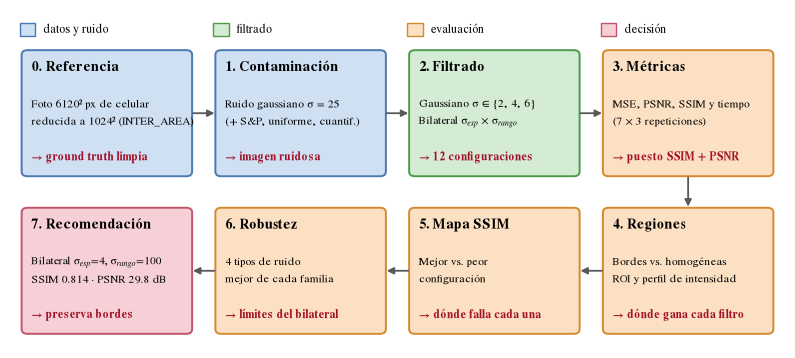

In [15]:
bloques = [
    ("0. Referencia", "Foto 6120² px de celular\nreducida a 1024² (INTER_AREA)", "→ ground truth limpia", "datos"),
    ("1. Contaminación", "Ruido gaussiano σ = 25\n(+ S&P, uniforme, cuantif.)", "→ imagen ruidosa", "datos"),
    ("2. Filtrado", "Gaussiano σ ∈ {2, 4, 6}\nBilateral σ$_{esp}$ × σ$_{rango}$", "→ 12 configuraciones", "filtro"),
    ("3. Métricas", "MSE, PSNR, SSIM y tiempo\n(7 × 3 repeticiones)", "→ puesto SSIM + PSNR", "eval"),
    ("7. Recomendación", f"{nombre_fig(CLAVE_MEJOR)}\nSSIM {mejor['SSIM']:.3f} · PSNR {mejor['PSNR']:.1f} dB", "→ preserva bordes", "decision"),
    ("6. Robustez", "4 tipos de ruido\nmejor de cada familia", "→ límites del bilateral", "eval"),
    ("5. Mapa SSIM", "Mejor vs. peor\nconfiguración", "→ dónde falla cada una", "eval"),
    ("4. Regiones", "Bordes vs. homogéneas\nROI y perfil de intensidad", "→ dónde gana cada filtro", "eval"),
]
colores_cat = {"datos": "#cfe0f3", "filtro": "#d5ecd4", "eval": "#fbe0c3", "decision": "#f6d0d6"}
bordes_cat = {"datos": "#4a78b0", "filtro": "#4c9a4a", "eval": "#d48a2c", "decision": "#c0566a"}
etiquetas_cat = {"datos": "datos y ruido", "filtro": "filtrado", "eval": "evaluación", "decision": "decisión"}

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.set_xlim(0, 4); ax.set_ylim(0, 2.15); ax.axis("off")
W, H = 0.86, 0.78
pos = [(i, 1) for i in range(4)] + [(i, 0) for i in range(4)]
for (tit, desc, sale, cat), (cx, fila) in zip(bloques, pos):
    x0, y0 = cx + (1 - W) / 2, fila * 1.0 + 0.1
    ax.add_patch(FancyBboxPatch((x0, y0), W, H, boxstyle="round,pad=0.01,rounding_size=0.03",
                                fc=colores_cat[cat], ec=bordes_cat[cat], lw=1.4))
    ax.text(x0 + 0.04, y0 + H - 0.1, tit, fontsize=10, weight="bold", va="center")
    ax.text(x0 + 0.04, y0 + H / 2, desc, fontsize=8.2, va="center")
    ax.text(x0 + 0.04, y0 + 0.11, sale, fontsize=8.2, va="center", color="#a3122a", weight="bold")
flecha = dict(arrowstyle="-|>", color="0.35", lw=1.3)
for i in range(3):
    ax.annotate("", xy=(i + 1 + (1 - W) / 2, 1.49), xytext=(i + 1 - (1 - W) / 2, 1.49), arrowprops=flecha)
    ax.annotate("", xy=(i + 1 - (1 - W) / 2, 0.49), xytext=(i + 1 + (1 - W) / 2, 0.49), arrowprops=flecha)
ax.annotate("", xy=(3.5, 0.1 + H), xytext=(3.5, 1.1), arrowprops=flecha)
for k, cat in enumerate(colores_cat):
    ax.add_patch(FancyBboxPatch((0.05 + k * 1.0, 1.98), 0.08, 0.08, boxstyle="square,pad=0", fc=colores_cat[cat], ec=bordes_cat[cat]))
    ax.text(0.17 + k * 1.0, 2.02, etiquetas_cat[cat], fontsize=8.5, va="center")
guardar_fig(fig, "pipeline.png")
plt.show()

## 10. Resumen de resultados

In [16]:
print(f"Ruidosa (σ={SIGMA_RUIDO}): MSE {base['MSE']:.1f} | PSNR {base['PSNR']:.2f} dB | SSIM {base['SSIM']:.3f}")
print("Mejor:", nombre(CLAVE_MEJOR), f"| MSE {mejor['MSE']:.1f} | PSNR {mejor['PSNR']:.2f} | SSIM {mejor['SSIM']:.3f} | {mejor['Tiempo [ms]']:.1f} ± {mejor['Desvío [ms]']:.1f} ms")
print("Mejor gaussiano:", nombre(CLAVE_GAUSS), f"| MSE {mejor_gauss['MSE']:.1f} | PSNR {mejor_gauss['PSNR']:.2f} | SSIM {mejor_gauss['SSIM']:.3f} | {mejor_gauss['Tiempo [ms]']:.1f} ± {mejor_gauss['Desvío [ms]']:.1f} ms")
print("Peor:", nombre(CLAVE_PEOR), f"| PSNR {peor['PSNR']:.2f} | SSIM {peor['SSIM']:.3f}")

Ruidosa (σ=25): MSE 527.4 | PSNR 20.91 dB | SSIM 0.302
Mejor: Bilateral σ_esp=4, σ_rango=100 | MSE 67.5 | PSNR 29.84 | SSIM 0.814 | 67.0 ± 3.8 ms
Mejor gaussiano: Gaussiano σ=2 | MSE 152.3 | PSNR 26.30 | SSIM 0.769 | 4.8 ± 0.4 ms
Peor: Bilateral σ_esp=2, σ_rango=20 | PSNR 21.52 | SSIM 0.326
